Found 28709 files belonging to 7 classes.
Detected Emotion Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Found 7178 files belonging to 7 classes.


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,423 (2.61 MB)

 Trainable params: 683,975 (2.61 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 18s 343ms/step - accuracy: 0.2410 - loss: 2.2837 - val_accuracy: 0.1646 - val_loss: 3.5925
Epoch 2/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 19s 324ms/step - accuracy: 0.2573 - loss: 1.8230 - val_accuracy: 0.1646 - val_loss: 5.4155
Epoch 3/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 21s 332ms/step - accuracy: 0.2997 - loss: 1.7534 - val_accuracy: 0.1646 - val_loss: 6.6631
Epoch 4/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 15s 332ms/step - accuracy: 0.3146 - loss: 1.7113 - val_accuracy: 0.1646 - val_loss: 5.3200
Epoch 5/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 15s 340ms/step - accuracy: 0.3323 - loss: 1.6786 - val_accuracy: 0.1906 - val_loss: 4.2070
Epoch 6/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 14s 320ms/step - accuracy: 0.3292 - loss: 1.6360 - val_accuracy: 0.2000 - val_loss: 4.6952
Epoch 7/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 21s 327ms/step - accuracy: 0.3528 - loss: 1.6057 - val_accuracy: 0.2573 - val_loss: 4.0898
Epoch 8/8
45/45 ━━━━━━━━━━━━━━━━━━━━ 14s 322ms/step - accuracy: 0.3615 - loss: 1.5735 - val_accuracy: 0.

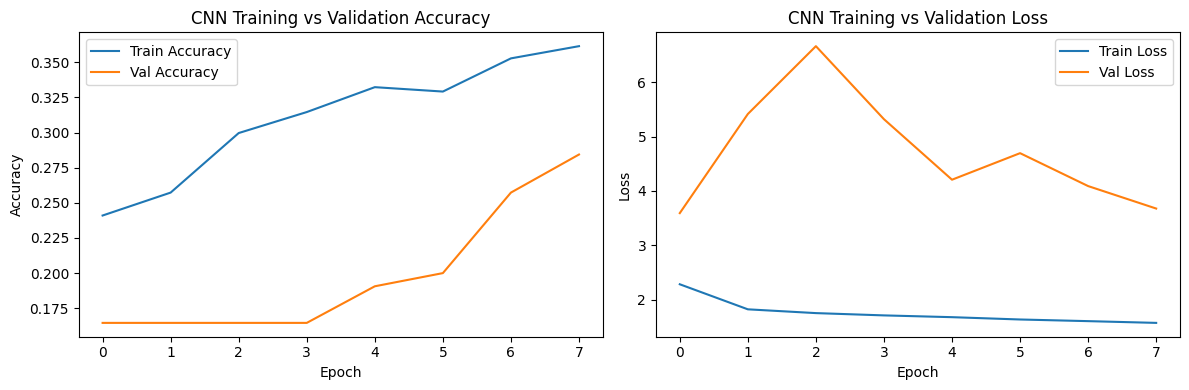

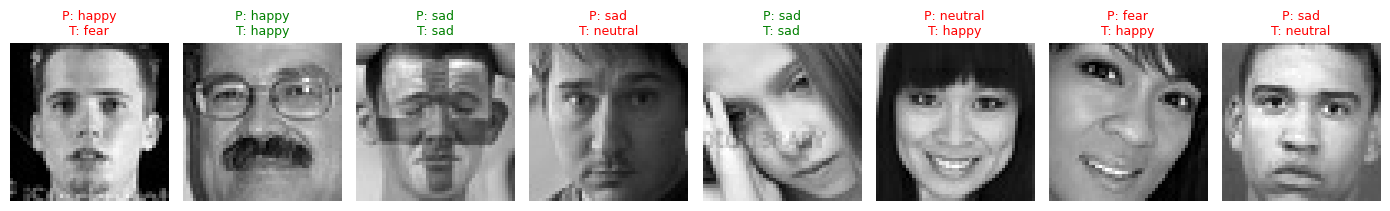

In [ ]:
import os
import time
import zipfile
import glob
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

start_time = time.time()

# ---------------------------------------------------------
# 1. EXTRACT DATASET TO LOCAL RUNTIME (/content/fer_data)
# ---------------------------------------------------------
extract_dir = '/content/fer_data'
zip_matches = glob.glob('/content/**/*.zip', recursive=True)

if not os.path.exists(extract_dir):
    assert len(zip_matches) > 0, "Please upload archive.zip to Colab Files first!"
    print(f"Extracting {zip_matches[0]}...")
    with zipfile.ZipFile(zip_matches[0], 'r') as z:
        z.extractall(extract_dir)

train_dir = glob.glob(f'{extract_dir}/**/train', recursive=True)[0]
test_dir = glob.glob(f'{extract_dir}/**/test', recursive=True)[0]

# ---------------------------------------------------------
# 2. LOAD SHUFFLED DATASETS & EXACT CLASS ORDER
# ---------------------------------------------------------
raw_train = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    color_mode='grayscale',
    image_size=(48, 48),
    batch_size=64,
    shuffle=True,
    seed=42
)
class_names = raw_train.class_names
print("Detected Emotion Classes:", class_names)

raw_val = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    color_mode='grayscale',
    image_size=(48, 48),
    batch_size=64,
    shuffle=True,
    seed=42
)

# Subset batches so CPU training finishes comfortably under 2 minutes
norm = layers.Rescaling(1.0 / 255.0)
train_ds = raw_train.take(45).map(lambda x, y: (norm(x), y)).cache().prefetch(tf.data.AUTOTUNE)
val_ds = raw_val.take(15).map(lambda x, y: (norm(x), y)).cache().prefetch(tf.data.AUTOTUNE)

# ---------------------------------------------------------
# 3. BUILD COMPACT CNN MODEL
# ---------------------------------------------------------
model = models.Sequential([
    layers.Input(shape=(48, 48, 1)),

    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(len(class_names), activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# ---------------------------------------------------------
# 4. TRAIN & EVALUATE ON CPU
# ---------------------------------------------------------
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    verbose=1
)

_, test_acc = model.evaluate(val_ds, verbose=0)
elapsed = time.time() - start_time
print(f"\nValidation/Test Accuracy: {test_acc * 100:.2f}%")
print(f"Total Execution Time: {elapsed:.1f} seconds")

# ---------------------------------------------------------
# 5. PLOT ACCURACY & LOSS CURVES
# ---------------------------------------------------------
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('CNN Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('CNN Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 6. VISUALIZE SAMPLE PREDICTIONS (P = Predicted, T = True)
# ---------------------------------------------------------
for imgs, lbls in val_ds.take(1):
    sample_imgs = imgs[:8].numpy()
    sample_labels = lbls[:8].numpy()

preds = np.argmax(model.predict(sample_imgs, verbose=0), axis=1)

plt.figure(figsize=(14, 4))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(sample_imgs[i].squeeze(), cmap='gray')
    is_correct = preds[i] == sample_labels[i]
    plt.title(
        f"P: {class_names[preds[i]]}\nT: {class_names[sample_labels[i]]}",
        color='green' if is_correct else 'red',
        fontsize=9
    )
    plt.axis('off')

plt.tight_layout()
plt.show()